# TrashCan — Exploratory Data Analysis (EDA)

**Objectif :** comprendre le dataset `material_version` avant le nettoyage et l'entraînement du détecteur de déchets.

Ce notebook analyse les annotations COCO originales. Il ne modifie aucun fichier du dataset.

## 0. Configuration

Lance ce notebook depuis le dossier `notebooks/` ou depuis la racine du projet.

In [29]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "dataset" / "material_version"
assert DATASET_PATH.exists(), f"Dataset introuvable : {DATASET_PATH}"

print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_PATH)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Project: c:\Users\mariem\Documents\trashcan-dl-mlops
Dataset: c:\Users\mariem\Documents\trashcan-dl-mlops\data\raw\dataset\material_version
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Chargement des annotations COCO et contrôle des fichiers

In [30]:
SPLITS = ["train", "val"]
image_rows, annotation_rows, category_rows = [], [], []
coco_by_split = {}

for split in SPLITS:
    json_path = DATASET_PATH / f"instances_{split}_trashcan.json"
    with open(json_path, "r", encoding="utf-8") as f:
        coco = json.load(f)
    coco_by_split[split] = coco

    for cat in coco["categories"]:
        category_rows.append({
            "split": split,
            "category_id": cat["id"],
            "class_name": cat["name"]
        })

    for img in coco["images"]:
        image_path = DATASET_PATH / split / Path(img["file_name"]).name
        image_rows.append({
            "split": split,
            "image_id": img["id"],
            "file_name": img["file_name"],
            "width": img["width"],
            "height": img["height"],
            "image_path": image_path,
            "video_id": re.search(r"(vid_\d+)", img["file_name"]).group(1)
                        if re.search(r"(vid_\d+)", img["file_name"]) else None,
            "frame_id": int(re.search(r"frame(\d+)", img["file_name"]).group(1))
                        if re.search(r"frame(\d+)", img["file_name"]) else None
        })

    for ann in coco["annotations"]:
        x, y, w, h = ann["bbox"]
        annotation_rows.append({
            "split": split,
            "annotation_id": ann["id"],
            "image_id": ann["image_id"],
            "category_id": ann["category_id"],
            "x": x, "y": y,
            "bbox_width": w, "bbox_height": h,
            "area": ann.get("area", w * h),
            "iscrowd": ann.get("iscrowd", 0)
        })

images_df = pd.DataFrame(image_rows)
annotations_df = pd.DataFrame(annotation_rows)
categories_df = pd.DataFrame(category_rows)

annotations_df = annotations_df.merge(
    categories_df[["split", "category_id", "class_name"]],
    on=["split", "category_id"],
    how="left",
    validate="many_to_one"
)

print("Images:", len(images_df))
print("Annotations:", len(annotations_df))
print("Classes:", sorted(categories_df["class_name"].unique()))
print("Missing image files:", (~images_df["image_path"].map(lambda p: p.is_file())).sum())
assert annotations_df["class_name"].notna().all(), "Category ID inconnu détecté."

Images: 7212
Annotations: 12336
Classes: ['animal_crab', 'animal_eel', 'animal_etc', 'animal_fish', 'animal_shells', 'animal_starfish', 'plant', 'rov', 'trash_etc', 'trash_fabric', 'trash_fishing_gear', 'trash_metal', 'trash_paper', 'trash_plastic', 'trash_rubber', 'trash_wood']
Missing image files: 0


## 2. Vue d'ensemble du dataset

In [31]:
overview = pd.DataFrame([
    {
        "Split": split,
        "Images": int((images_df["split"] == split).sum()),
        "Annotations": int((annotations_df["split"] == split).sum())
    }
    for split in SPLITS
])
overview["Objects per image"] = (
    overview["Annotations"] / overview["Images"]
).round(2)
display(overview)
print("Total images:", len(images_df))
print("Total annotations:", len(annotations_df))
print("Total classes:", categories_df["class_name"].nunique())

,Split,Images,Annotations,Objects per image
0,train,6008,9741,1.62
1,val,1204,2595,2.16


Total images: 7212
Total annotations: 12336
Total classes: 16


## 3. Intégrité des annotations et bounding boxes hors limites

Les débordements sont mesurés, pas supprimés ici. Le notebook Cleaning corrigera les coordonnées sans jeter automatiquement les objets.

In [32]:
bbox_check = annotations_df.merge(
    images_df[["split", "image_id", "width", "height"]],
    on=["split", "image_id"],
    how="left",
    validate="many_to_one"
)
bbox_check["overflow_left"] = (-bbox_check["x"]).clip(lower=0)
bbox_check["overflow_top"] = (-bbox_check["y"]).clip(lower=0)
bbox_check["overflow_right"] = (
    bbox_check["x"] + bbox_check["bbox_width"] - bbox_check["width"]
).clip(lower=0)
bbox_check["overflow_bottom"] = (
    bbox_check["y"] + bbox_check["bbox_height"] - bbox_check["height"]
).clip(lower=0)

overflow_cols = ["overflow_left", "overflow_top", "overflow_right", "overflow_bottom"]
outside_mask = bbox_check[overflow_cols].gt(0).any(axis=1)
integrity = pd.DataFrame({
    "Check": [
        "Missing image files",
        "Duplicate image IDs within split",
        "Duplicate annotation IDs within split",
        "Unknown category references",
        "Non-positive bbox dimensions",
        "Bounding boxes outside image"
    ],
    "Count": [
        int((~images_df["image_path"].map(lambda p: p.is_file())).sum()),
        int(images_df.duplicated(["split", "image_id"]).sum()),
        int(annotations_df.duplicated(["split", "annotation_id"]).sum()),
        int(annotations_df["class_name"].isna().sum()),
        int(((annotations_df["bbox_width"] <= 0) | (annotations_df["bbox_height"] <= 0)).sum()),
        int(outside_mask.sum())
    ]
})
display(integrity)
print("Maximum overflow (pixels):", bbox_check[overflow_cols].to_numpy().max())
print("Outside bbox by edge:")
display((bbox_check[overflow_cols] > 0).sum().rename("Count").to_frame())

,Check,Count
0,Missing image files,0
1,Duplicate image IDs within split,0
2,Duplicate annotation IDs within split,0
3,Unknown category references,0
4,Non-positive bbox dimensions,0
5,Bounding boxes outside image,3346


Maximum overflow (pixels): 0.9980392156862763
Outside bbox by edge:


,Count
overflow_left,0
overflow_top,0
overflow_right,1307
overflow_bottom,2572


## 4. Distribution des classes et déséquilibre

Le projet cible les huit classes `trash_*`. Les autres classes (ROV, animaux, plantes) sont utiles pour comprendre le dataset source, mais ne seront pas des classes de sortie du modèle.

,Train objects,Val objects,Total objects,Train images,Val images,Total images,Object share (%)
class_name,,,,,,,
rov,2653,664,3317,2241,480,2721,26.89
trash_etc,1630,409,2039,1439,301,1740,16.53
trash_plastic,1490,374,1864,1412,341,1753,15.11
trash_metal,901,225,1126,879,214,1093,9.13
animal_fish,611,153,764,543,101,644,6.19
plant,405,102,507,384,98,482,4.11
animal_starfish,274,124,398,87,47,134,3.23
animal_eel,267,76,343,185,74,259,2.78
trash_wood,271,69,340,257,67,324,2.76


,Train objects,Val objects,Total objects,Train images,Val images,Total images,Object share (%)
class_name,,,,,,,
trash_etc,1630,409,2039,1439,301,1740,16.53
trash_plastic,1490,374,1864,1412,341,1753,15.11
trash_metal,901,225,1126,879,214,1093,9.13
trash_wood,271,69,340,257,67,324,2.76
trash_fabric,247,67,314,213,56,269,2.55
trash_fishing_gear,127,69,196,110,57,167,1.59
trash_paper,154,39,193,129,38,167,1.56
trash_rubber,113,29,142,113,29,142,1.15


Imbalance ratio (all classes): 23.36
Imbalance ratio (8 trash classes): 14.36


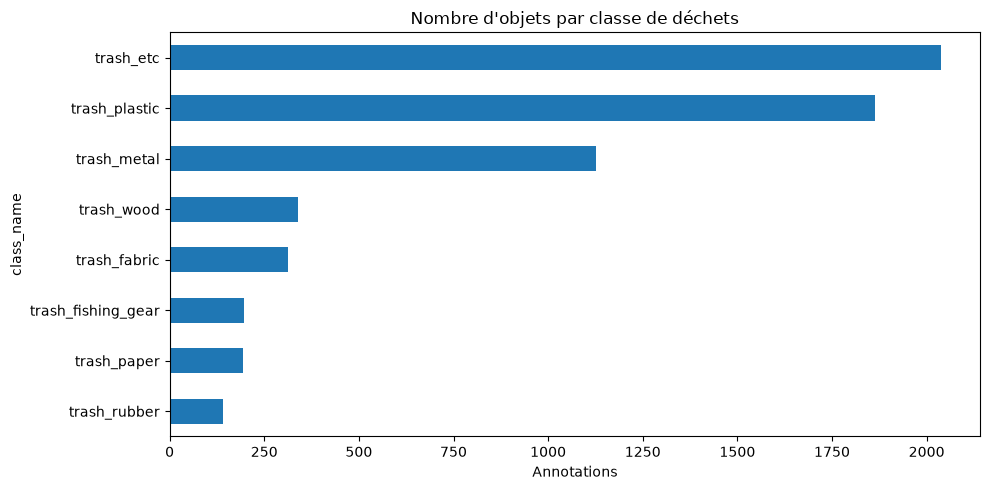

In [33]:
object_counts = (
    annotations_df.groupby(["class_name", "split"]).size()
    .unstack(fill_value=0)
)
image_counts = (
    annotations_df.groupby(["class_name", "split"])["image_id"]
    .nunique().unstack(fill_value=0)
)
class_summary = pd.DataFrame(index=object_counts.index)
class_summary["Train objects"] = object_counts.get("train", 0)
class_summary["Val objects"] = object_counts.get("val", 0)
class_summary["Total objects"] = class_summary["Train objects"] + class_summary["Val objects"]
class_summary["Train images"] = image_counts.get("train", 0)
class_summary["Val images"] = image_counts.get("val", 0)
class_summary["Total images"] = class_summary["Train images"] + class_summary["Val images"]
class_summary["Object share (%)"] = (
    100 * class_summary["Total objects"] / class_summary["Total objects"].sum()
).round(2)
display(class_summary.sort_values("Total objects", ascending=False))

trash_classes = [
    "trash_etc", "trash_plastic", "trash_metal", "trash_wood",
    "trash_fabric", "trash_fishing_gear", "trash_paper", "trash_rubber"
]
trash_summary = class_summary.loc[trash_classes].sort_values("Total objects", ascending=False)
display(trash_summary)
print("Imbalance ratio (all classes):",
      round(class_summary["Total objects"].max() / class_summary["Total objects"].min(), 2))
print("Imbalance ratio (8 trash classes):",
      round(trash_summary["Total objects"].max() / trash_summary["Total objects"].min(), 2))

ax = trash_summary["Total objects"].sort_values().plot(
    kind="barh", figsize=(10, 5), title="Nombre d'objets par classe de déchets"
)
ax.set_xlabel("Annotations")
plt.tight_layout()
plt.show()

## 5. Analyse du split Train / Validation et fuite entre vidéos

Des frames provenant d'une même vidéo peuvent être très similaires. Si une vidéo apparaît dans les deux splits, les métriques de validation peuvent être trop optimistes.

In [34]:
train_videos = set(images_df.loc[images_df["split"] == "train", "video_id"].dropna())
val_videos = set(images_df.loc[images_df["split"] == "val", "video_id"].dropna())
shared_videos = train_videos & val_videos

print("Train unique videos:", len(train_videos))
print("Validation unique videos:", len(val_videos))
print("Shared videos:", len(shared_videos))
print("Only train:", len(train_videos - val_videos))
print("Only validation:", len(val_videos - train_videos))

Train unique videos: 306
Validation unique videos: 133
Shared videos: 127
Only train: 179
Only validation: 6


### 5.1 Distance temporelle entre frames des deux splits

,Frame distance
count,1182.00
mean,6.30
std,9.35
min,1.00
25%,1.00
50%,3.00
75%,6.00
max,70.00


,Threshold (frames),Validation frames,Percentage (%)
0,1,312,26.40
1,5,833,70.47
2,10,1016,85.96
3,30,1135,96.02
4,60,1179,99.75


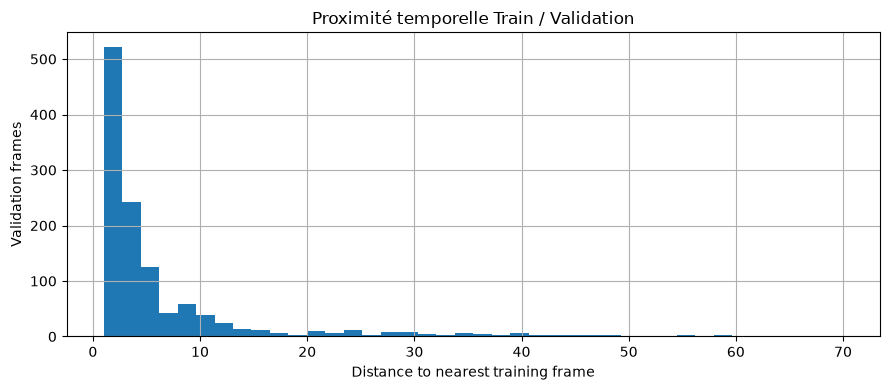

In [35]:
frame_data = images_df.dropna(subset=["video_id", "frame_id"]).copy()
train_frames = frame_data[frame_data["split"] == "train"]
val_frames = frame_data[frame_data["split"] == "val"]
distance_rows = []

for video_id in sorted(shared_videos):
    train_ids = np.sort(train_frames.loc[train_frames["video_id"] == video_id, "frame_id"].to_numpy())
    val_ids = val_frames.loc[val_frames["video_id"] == video_id, "frame_id"].to_numpy()
    if len(train_ids) == 0 or len(val_ids) == 0:
        continue
    pos = np.searchsorted(train_ids, val_ids)
    left = np.clip(pos - 1, 0, len(train_ids) - 1)
    right = np.clip(pos, 0, len(train_ids) - 1)
    nearest = np.minimum(np.abs(val_ids - train_ids[left]), np.abs(val_ids - train_ids[right]))
    for frame, distance in zip(val_ids, nearest):
        distance_rows.append({
            "video_id": video_id,
            "val_frame": int(frame),
            "nearest_train_distance": int(distance)
        })

frame_distances = pd.DataFrame(distance_rows)
if len(frame_distances):
    display(frame_distances["nearest_train_distance"].describe().to_frame("Frame distance").round(2))
    thresholds = [1, 5, 10, 30, 60]
    proximity = pd.DataFrame({
        "Threshold (frames)": thresholds,
        "Validation frames": [
            int((frame_distances["nearest_train_distance"] <= t).sum())
            for t in thresholds
        ]
    })
    proximity["Percentage (%)"] = (
        100 * proximity["Validation frames"] / len(frame_distances)
    ).round(2)
    display(proximity)
    frame_distances["nearest_train_distance"].hist(bins=40, figsize=(9, 4))
    plt.xlabel("Distance to nearest training frame")
    plt.ylabel("Validation frames")
    plt.title("Proximité temporelle Train / Validation")
    plt.tight_layout()
    plt.show()
else:
    print("Pas de vidéos communes ou pas de frame_id exploitable.")

## 6. Résolution des images

In [36]:
images_df["resolution"] = images_df["width"].astype(str) + "x" + images_df["height"].astype(str)
display(images_df.groupby(["split", "resolution"]).size().unstack(fill_value=0))
display(images_df.groupby("split")[["width", "height"]].agg(["min", "median", "max", "mean"]).round(2))
print(images_df["resolution"].value_counts())

resolution,480x270,480x360
split,,
train,3000,3008
val,967,237


width                    height                    
        min median  max   mean    min median  max    mean
split                                                    
train   480  480.0  480  480.0    270  360.0  360  315.06
val     480  480.0  480  480.0    270  270.0  360  287.72

resolution
480x270    3967
480x360    3245
Name: count, dtype: int64


## 7. Taille relative des bounding boxes

In [37]:
bbox_analysis = bbox_check.copy()
bbox_analysis["bbox_width_ratio"] = bbox_analysis["bbox_width"] / bbox_analysis["width"]
bbox_analysis["bbox_height_ratio"] = bbox_analysis["bbox_height"] / bbox_analysis["height"]
bbox_analysis["bbox_area_ratio"] = (
    bbox_analysis["bbox_width"] * bbox_analysis["bbox_height"]
) / (bbox_analysis["width"] * bbox_analysis["height"])

display(bbox_analysis[[
    "bbox_width", "bbox_height", "area",
    "bbox_width_ratio", "bbox_height_ratio", "bbox_area_ratio"
]].describe().round(4))

display(
    bbox_analysis[bbox_analysis["class_name"].isin(trash_classes)]
    .groupby("class_name")
    .agg(
        objects=("annotation_id", "count"),
        median_width=("bbox_width", "median"),
        median_height=("bbox_height", "median"),
        median_area_ratio=("bbox_area_ratio", "median")
    ).sort_values("median_area_ratio")
)

,bbox_width,bbox_height,area,bbox_width_ratio,bbox_height_ratio,bbox_area_ratio
count,12336.0000,12336.0000,12336.0000,12336.0000,12336.0000,12336.0000
mean,137.2581,92.7265,9482.6406,0.2860,0.3031,0.1246
std,126.8361,77.2454,14967.5180,0.2642,0.2490,0.1840
min,2.9961,2.9961,4.9882,0.0062,0.0111,0.0001
25%,44.9719,34.9875,959.5511,0.0937,0.1148,0.0108
50%,85.9961,62.9961,2913.7135,0.1792,0.2083,0.0412
75%,195.9939,135.9857,11757.6694,0.4083,0.4332,0.1637
max,480.9961,360.9961,122745.4442,1.0021,1.0037,1.0058


,objects,median_width,median_height,median_area_ratio
class_name,,,,
trash_rubber,142,60.971968,43.928889,0.015519
trash_etc,2039,60.986868,42.991827,0.016966
trash_metal,1126,60.991859,50.846402,0.021192
trash_paper,193,74.996078,53.996078,0.028885
trash_plastic,1864,76.996078,62.996014,0.034599
trash_wood,340,124.490487,83.982397,0.064709
trash_fabric,314,113.489583,74.985969,0.069612
trash_fishing_gear,196,136.996078,96.485457,0.092038


## 8. ROV uniquement et ROV avec d'autres objets

In [38]:
image_class_sets = (
    annotations_df.groupby(["split", "image_id"])["class_name"]
    .agg(set)
)
rov_only_count = int(image_class_sets.apply(lambda s: s == {"rov"}).sum())
rov_with_others_count = int(
    image_class_sets.apply(lambda s: "rov" in s and len(s) > 1).sum()
)
print("Images ROV uniquement:", rov_only_count)
print("Images ROV + autre objet:", rov_with_others_count)

Images ROV uniquement: 730
Images ROV + autre objet: 1991


## 9. Nombre d'objets par image

In [39]:
objects_per_image = (
    annotations_df.groupby(["split", "image_id"]).size()
    .reset_index(name="number_of_objects")
)
display(objects_per_image.groupby("split")["number_of_objects"].describe().round(2))

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,6008.0,1.62,1.18,1.0,1.0,1.0,2.0,19.0
val,1204.0,2.16,1.65,1.0,1.0,2.0,3.0,19.0


## 10. Position des objets dans l'image

In [40]:
position_df = bbox_analysis.copy()
position_df["center_x"] = (
    position_df["x"] + position_df["bbox_width"] / 2
) / position_df["width"]
position_df["center_y"] = (
    position_df["y"] + position_df["bbox_height"] / 2
) / position_df["height"]

def get_position_zone(row):
    horizontal = "Left" if row["center_x"] < 1/3 else ("Center" if row["center_x"] < 2/3 else "Right")
    vertical = "Top" if row["center_y"] < 1/3 else ("Middle" if row["center_y"] < 2/3 else "Bottom")
    return f"{vertical}-{horizontal}"

position_df["position_zone"] = position_df.apply(get_position_zone, axis=1)
display(position_df["position_zone"].value_counts().to_frame("Number of objects"))
display(position_df[["center_x", "center_y"]].describe().round(4))

,Number of objects
position_zone,
Middle-Center,3480
Bottom-Center,1891
Middle-Right,1432
Bottom-Left,1390
Middle-Left,1349
Bottom-Right,1254
Top-Center,650
Top-Right,612
Top-Left,278


,center_x,center_y
count,12336.0000,12336.0000
mean,0.5051,0.5906
std,0.2352,0.2110
min,0.0135,0.0167
25%,0.3375,0.4592
50%,0.5010,0.5926
75%,0.6812,0.7500
max,0.9938,0.9926


## 11. Inspection visuelle des annotations

Vérifie visuellement que les rectangles sont positionnés sur les objets. Cette étape est importante avant le Cleaning.

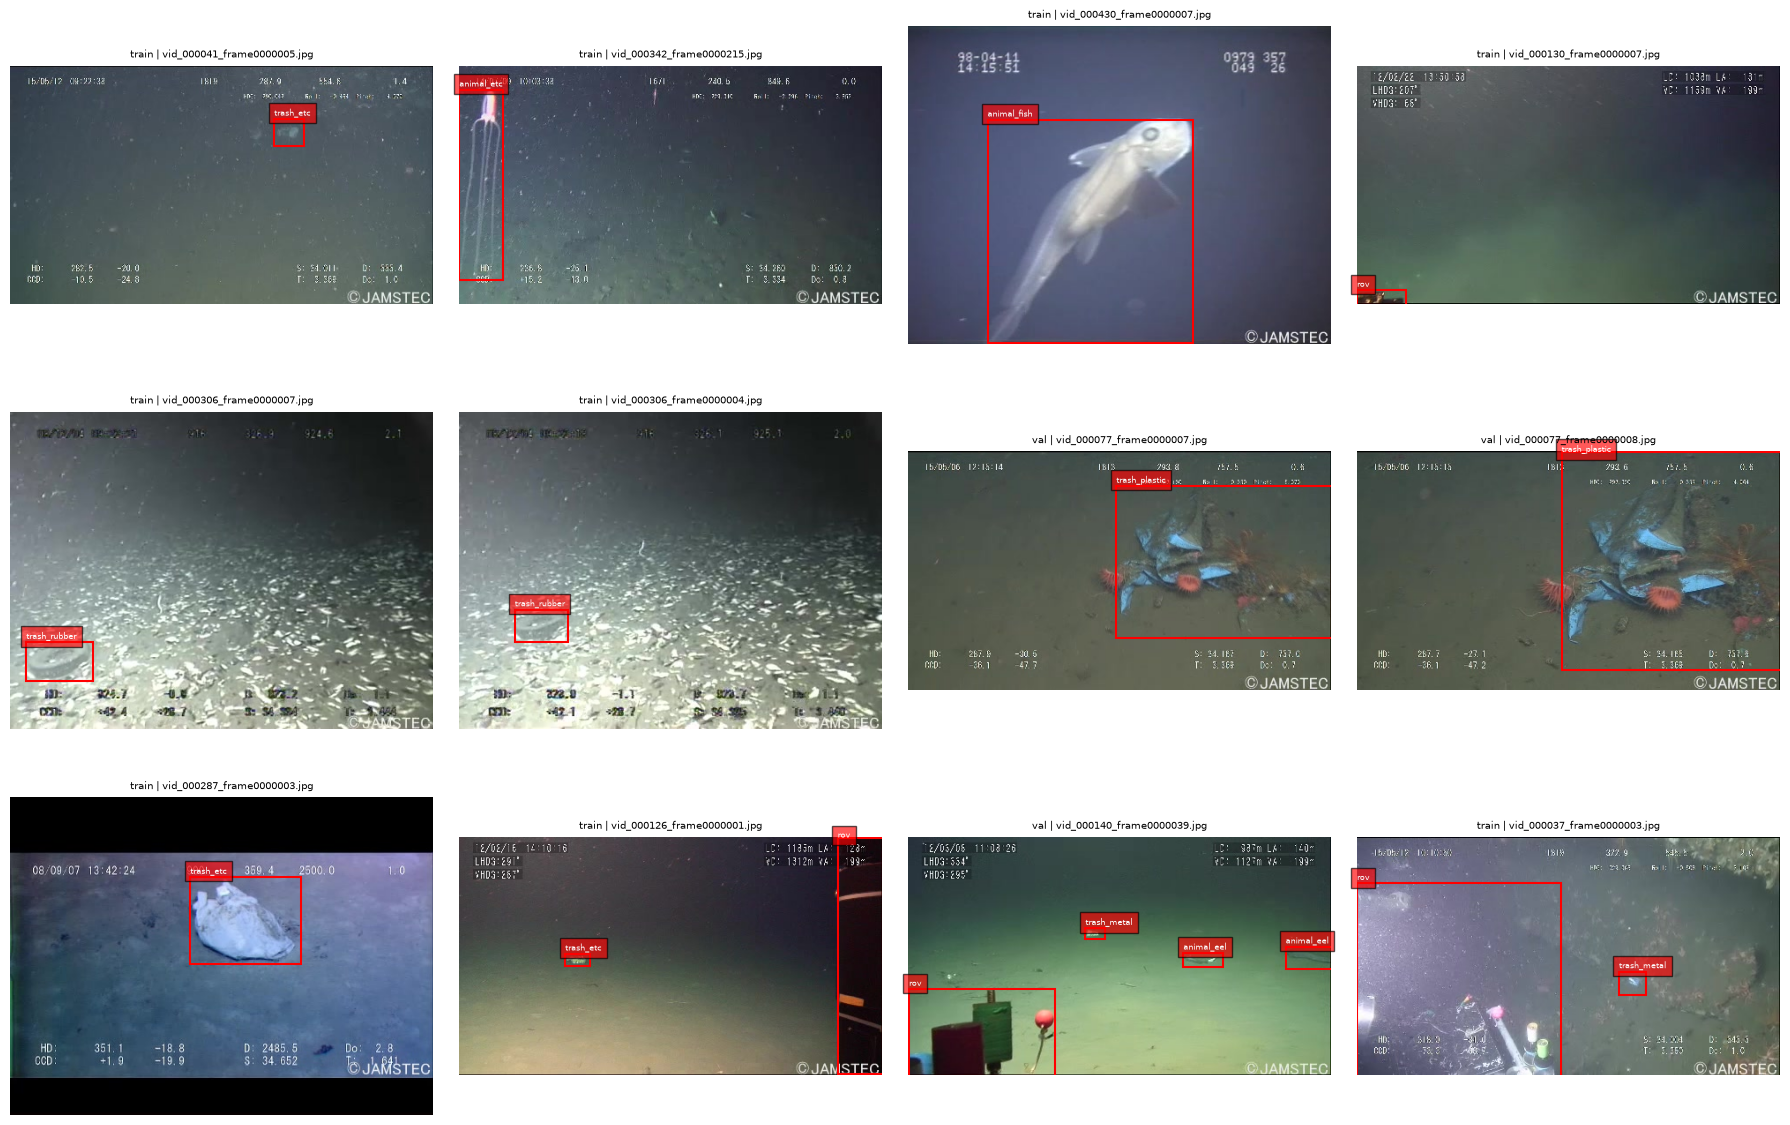

In [41]:
sample = images_df.sample(n=min(12, len(images_df)), random_state=42).reset_index(drop=True)
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for ax, (_, img_row) in zip(axes, sample.iterrows()):
    image = Image.open(img_row["image_path"]).convert("RGB")
    ax.imshow(image)
    anns = annotations_df[
        (annotations_df["split"] == img_row["split"]) &
        (annotations_df["image_id"] == img_row["image_id"])
    ]
    for _, ann in anns.iterrows():
        rect = plt.Rectangle(
            (ann["x"], ann["y"]), ann["bbox_width"], ann["bbox_height"],
            fill=False, edgecolor="red", linewidth=1.5
        )
        ax.add_patch(rect)
        ax.text(ann["x"], max(0, ann["y"] - 4), ann["class_name"],
                color="white", fontsize=6,
                bbox={"facecolor": "red", "alpha": 0.65})
    ax.set_title(f'{img_row["split"]} | {img_row["file_name"]}', fontsize=7)
    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 12. Export des résultats EDA

Les CSV sont enregistrés dans `reports/eda_results/`. Le dataset original n'est pas modifié.

In [42]:
EDA_DIR = PROJECT_ROOT / "reports" / "eda_results"
EDA_DIR.mkdir(parents=True, exist_ok=True)

class_summary.to_csv(EDA_DIR / "class_distribution_all_classes.csv", encoding="utf-8-sig")
trash_summary.to_csv(EDA_DIR / "class_distribution_trash_only.csv", encoding="utf-8-sig")
bbox_analysis.groupby("class_name").agg(
    number_of_objects=("annotation_id", "count"),
    mean_width=("bbox_width", "mean"),
    median_width=("bbox_width", "median"),
    mean_height=("bbox_height", "mean"),
    median_height=("bbox_height", "median"),
    mean_area_ratio=("bbox_area_ratio", "mean"),
    median_area_ratio=("bbox_area_ratio", "median")
).to_csv(EDA_DIR / "bbox_statistics_by_class.csv", encoding="utf-8-sig")
objects_per_image.to_csv(EDA_DIR / "objects_per_image.csv", index=False, encoding="utf-8-sig")
position_df.to_csv(EDA_DIR / "object_positions.csv", index=False, encoding="utf-8-sig")
if len(frame_distances):
    frame_distances.to_csv(EDA_DIR / "temporal_frame_distances.csv", index=False, encoding="utf-8-sig")

print("EDA exports saved to:", EDA_DIR)
print("Files:", sorted(p.name for p in EDA_DIR.iterdir()))

EDA exports saved to: c:\Users\mariem\Documents\trashcan-dl-mlops\reports\eda_results
Files: ['bbox_statistics_by_class.csv', 'class_distribution_all_classes.csv', 'class_distribution_trash_only.csv', 'object_positions.csv', 'objects_per_image.csv', 'temporal_frame_distances.csv']


## Conclusion EDA — décisions pour le projet

1. Le modèle de Phase A doit prédire uniquement les 8 classes `trash_*`.
2. Le split original présente un chevauchement de vidéos : il faut refaire Train / Validation par vidéo.
3. Les débordements de bounding boxes sont de très faible amplitude dans les données observées : les corriger par clipping plutôt que supprimer automatiquement les annotations.
4. Le dataset est déséquilibré : suivre les métriques par classe, pas seulement la métrique globale.
5. Garder les images sans annotation de déchet comme exemples négatifs, sauf les images contenant uniquement le ROV qui sont retirées dans le Cleaning final.